In [1]:
import os
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import json
import shutil
import itertools
import pandas as pd
from tqdm import tqdm

from typing import Dict, Tuple, Any

from Components.System import SimpleSquareExample 
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCostQuadraticYield
from Components.Controllers import TimeVaryingCost_LQRc_RHG

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.printoptions(linewidth=np.inf)

# Create model

In [3]:
parameter_file = "run_data/two_wells_analysis/finite_welfare/run_20251107-112119/two_wells_analysis_parameters_changed.json"
crop_repartition = np.array([[1., 1.], [0., 0.], [0., 0.], [0., 0.]])

In [4]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")

# Step command

In [5]:
heads = [system.get_heads_at_wells()]
for t in range(300):
    system.apply_command(-100*np.array([[1,1]]).T)
    heads.append(system.get_heads_at_wells())

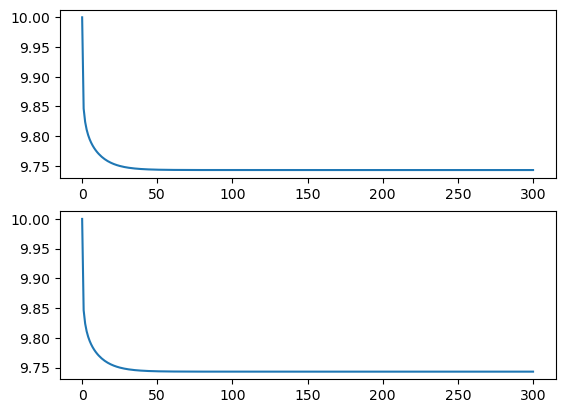

In [6]:
heads = np.array(heads)

fig, ax = plt.subplots(2,1)
ax[0].plot(heads[:,0])
ax[1].plot(heads[:,1])

plt.show()

In [7]:
x_tau = (heads[0,:] - heads[-1,:]) * (1 - 1/np.e)
x_tau

array([0.16243929, 0.1623591 ], dtype=float32)

In [8]:
tau = np.array([np.searchsorted(heads[0,0] - heads[:,0], x_tau[0]), np.searchsorted(heads[0,1] - heads[:,1], x_tau[1])])-1

In [9]:
tau

array([1, 1])

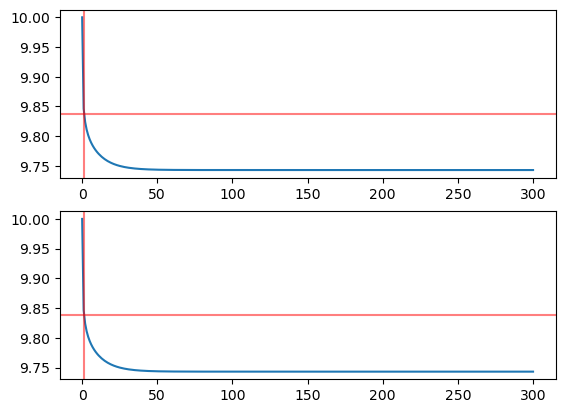

In [10]:
heads = np.array(heads)

fig, ax = plt.subplots(2,1)
ax[0].plot(heads[:,0])
ax[1].plot(heads[:,1])

ax[0].axhline(heads[0,0] - x_tau[0], color='r', alpha=0.5)
ax[0].axvline(tau[0], color='r', alpha=0.5)

ax[1].axhline(heads[0,1] - x_tau[1], color='r', alpha=0.5)
ax[1].axvline(tau[1], color='r', alpha=0.5)

plt.show()

# Change conductivity

In [5]:
dir, file = os.path.split(parameter_file)
name, ext = file.split('.')
new_parameter_file = dir + '/' + name + '_tmp' + '.' + ext
shutil.copyfile(parameter_file, new_parameter_file)

'run_data/two_wells_analysis/finite_welfare/run_20251107-112119/two_wells_analysis_parameters_changed_tmp.json'

In [6]:
with open(new_parameter_file, 'r+') as f:
    data = json.load(f)
    # modify field
    data['physical']['hk'] = 0.1
    data['physical']['sy'] = 0.1
    # overwrite file
    f.seek(0)
    json.dump(data, f, indent=4)
    f.truncate()

In [7]:
new_system = SimpleSquareExample(new_parameter_file, boundary_condition="Constant Head")

In [87]:
new_heads = [new_system.get_heads_at_wells()]
for t in range(300):
    new_system.apply_command(-100*np.array([[1,1]]).T)
    new_heads.append(new_system.get_heads_at_wells())
new_heads = np.array(new_heads)

In [88]:
new_x_tau = (new_heads[0,:] - new_heads[-1,:]) * (1 - 1/np.e)
new_tau = np.array([np.searchsorted(new_heads[0,0] - new_heads[:,0], new_x_tau[0]), np.searchsorted(new_heads[0,1] - new_heads[:,1], new_x_tau[1])])-1

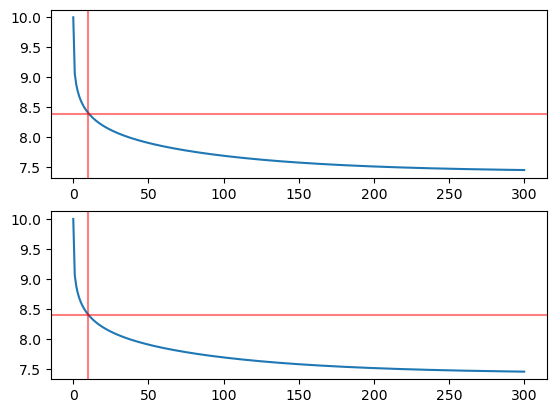

In [89]:
fig, ax = plt.subplots(2,1)
ax[0].plot(new_heads[:,0])
ax[1].plot(new_heads[:,1])

ax[0].axhline(new_heads[0,0] - new_x_tau[0], color='r', alpha=0.5)
ax[0].axvline(new_tau[0], color='r', alpha=0.5)

ax[1].axhline(new_heads[0,1] - new_x_tau[1], color='r', alpha=0.5)
ax[1].axvline(new_tau[1], color='r', alpha=0.5)

plt.show()

In [90]:
new_tau

array([10, 10])

# Impact of parameters on 1st step pumping command (between H=1 and H=30)

In [8]:
parameters_set = {
    "land_size" : [(10,10), (100, 100), (500, 500)],
    "selling_price": [0.1, 0.5, 1, 5, 10],
    "max_yield": [0.1, 0.5, 1, 2, 10],
    "max_Kc": [0.1, 0.5, 1, 2, 10],
    "intermediate_yield": [0.9, 0.92, 0.95, 0.98, 0.99],
    "electricity_price": [0.1, 0.5, 1, 5, 10],
    "alpha_price": [1],
    "conductivity": [0.1, 0.5, 1.]
}
crops = np.array([[1., 1.], [0., 0.], [0., 0.], [0., 0.]])

In [9]:
parameter_file = "/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/Setup/two_wells_analysis_quadCost_parameters_var.json"
dir, file = os.path.split(parameter_file)
name, ext = file.split('.')
new_parameter_file = dir + '/' + name + '_tmp' + '.' + ext

In [10]:
product_len = 1
for param in parameters_set.values():
    product_len *= len(param)
product_len

28125

In [61]:
keys = list(parameters_set.keys())
values = list(parameters_set.values())

rows = list(itertools.product(*values))
df = pd.DataFrame(rows, columns=keys)

In [62]:
df["q_0_1_1"] = np.nan
df["q_0_1_2"] = np.nan
df["q_0_10_1"] = np.nan
df["q_0_10_2"] = np.nan

In [11]:

model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)
Ymax_v_c_t = quad_cost._yield_max([0])
ETmax_v_c_t = quad_cost._local_evapotranspiration([0]).T
Y_q_v_c_t = quad_cost._yield_intermediate([0])

def _get_yield_response_to_water_coefficients(settings: Dict[str, Any]) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """ Coefficients of the quadratic function. """
    y = settings['max_yield']
    kc = settings['max_Kc']
    yi = settings['intermediate_yield']
    # Get yield data
    Ymax_v_c_t[0,0] = y             # [n_crop, horizon]
    ETmax_v_c_t[0,0] = kc*5         # [n_crop, horizon]
    Y_q_v_c_t[0,0] = yi             # [n_crop, horizon]
    # Safely inverse values
    inv_ETmax_v_c_t = np.where(ETmax_v_c_t !=0, 1/ETmax_v_c_t, 0)
    inv_quad_ETmax_v_c_t = inv_ETmax_v_c_t * inv_ETmax_v_c_t
    # Construct local coefficients
    d = ((1 - quad_cost.intermediate_irrigation_value)**2)
    a_yield_v_c_t = - Ymax_v_c_t * inv_quad_ETmax_v_c_t * (1 - Y_q_v_c_t) / d
    b_yield_v_c_t = 2* Ymax_v_c_t * inv_ETmax_v_c_t * (1 - Y_q_v_c_t) / d
    c_yield_v_c_t = Ymax_v_c_t * (1 - (1 - Y_q_v_c_t) / d)
    # Scale to obtain global coefficients
    if type(settings['land_size']) == str:
        land_surface = np.array(eval(settings['land_size']))
    else:
        land_surface = np.array(settings['land_size'])
    crop_surface = (land_surface * quad_cost.crop_repartition).T            # [n_agent, n_crops]
    inv_crop_surface = np.divide(1.0, crop_surface,
                                 out=np.zeros_like(crop_surface),
                                 where=crop_surface!=0)                     # [n_agent, n_crops]
    null_surface_mask = (crop_surface != 0).astype(float)                   # [n_agent, n_crops]
    a_yield_v_c_t = inv_crop_surface[:, :, None] * a_yield_v_c_t[None, :, :]
    b_yield_v_c_t = null_surface_mask[:, :, None] * b_yield_v_c_t[None, :, :]
    c_yield_v_c_t = crop_surface[:, :, None] * c_yield_v_c_t[None, :, :]
    return a_yield_v_c_t, b_yield_v_c_t, c_yield_v_c_t                      # [n_agent, n_crops, horizon]

def _compute_irrigation_cost_matrices(settings):
    # Get cost data
    a_yield_v_c_t, b_yield_v_c_t, _ = _get_yield_response_to_water_coefficients(settings)    # [n_agent, n_crop, horizon]
    # Arrange a in square diagonal matrices of size n_crops for all v,t
    diag_a_yield_v_c_t = [sp.diags(a_yield_v_c_t[v,:,0].flatten())
                          for v in range(quad_cost.n_agent)]
    # Arrange b in flat matrices of size n_crops for all v,t
    diag_b_yield_v_c_t = [b_yield_v_c_t[v,:,0].flatten().reshape(1, quad_cost.n_crops)
                    for v in range(quad_cost.n_agent)]
    # Form cost matrices
    spv = settings['selling_price']
    Ri_v = [- (spv * u2c.T  @ a_yield @ u2c)
                    for u2c, a_yield in
                    zip(quad_cost.input_to_crop_irrigation_v, diag_a_yield_v_c_t)]
    Li_v = [spv * b_yield @ u2c
                    for u2c, b_yield in
                    zip(quad_cost.input_to_crop_irrigation_v, diag_b_yield_v_c_t)]
    return Ri_v, Li_v

def repeat_matrix(mat_v):
    mat_v_1 = [[list(mat_v)[0]], [list(mat_v)[1]]]
    if type(mat_v[0]) == np.ndarray:
        mat_v_10 = list(np.kron(mat_v, np.ones((10,1,1))))
        mat_v_10 = [mat_v_10[:10], mat_v_10[10:]]
    else:
        mat_v_10 = list(np.kron(mat_v, np.ones((10,))))
        mat_v_10 = [mat_v_10[:10], mat_v_10[10:]]    
    return mat_v_1, mat_v_10

In [12]:
x_0 = model.get_initial_state()

In [ ]:
pbar = tqdm(total=(len(df)), position=0, desc="Scenario")
alpha_step = len(parameters_set['conductivity'])

for conductivity in parameters_set["conductivity"]:
    # Update model
    shutil.copyfile(parameter_file, new_parameter_file)
    with open(new_parameter_file, 'r+') as f:
        data = json.load(f)
        # modify field
        data['physical']['hk'] = conductivity
        # overwrite file
        f.seek(0)
        json.dump(data, f, indent=4)
        f.truncate()
    model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
    quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)
    # Initialize Controller
    controller_1 = TimeVaryingCost_LQRc_RHG(
        parameter_file,
        model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
        model.H_x, model.h_x, model.H_u_v, model.h_u_v,
        model.H_xu_x, model.H_xu_u, model.h_xu,
        solver='fbrs',
        overwrite_time_horizon=1
    )
    controller_10 = TimeVaryingCost_LQRc_RHG(
        parameter_file,
        model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
        model.H_x, model.h_x, model.H_u_v, model.h_u_v,
        model.H_xu_x, model.H_xu_u, model.h_xu,
        solver='fbrs',
        overwrite_time_horizon=10
    )
    # Model useful variables
    A = model.A
    Id_minus_A_inv = np.linalg.inv(np.eye(A.shape[0]) - A)
    B0, B1 = model.B_v
    Cinvt = model.C.T @ Id_minus_A_inv.T
    # Iterate over all other parameters
    df_dist = df[df["conductivity"] == conductivity]
    for idx, row in df_dist.iterrows():
        pbar.update(1)
        # Skip already computed values
        if not np.isnan(df.at[idx, "q_0_1_1"]):
            continue
        # Construct quadratic and linear cost matrices
        Ri_v_quad, Li_v_quad = _compute_irrigation_cost_matrices(row)
        # Scale pumping cost
        ep = 10e-5 * row['electricity_price'] / quad_cost.extraction_cost[0]
        Rp_v  = ep * np.array(quad_cost.Rp_v)
        Rp_v_minus = ep * np.array(quad_cost.Rp_v_minus)
        Mp_v  = ep * np.array(quad_cost.Mp_v)
        Lp_v  = ep * np.array(quad_cost.Lp_v)
        Rp_v_minus_1, Rp_v_minus_10 = repeat_matrix(Rp_v_minus)
        Mp_v_1, Mp_v_10 = repeat_matrix(Mp_v)
        # Iterate over varying quadratic reward importance
        for i_alpha, alpha in enumerate(parameters_set["alpha_price"]):   # TODO: add linear cost if we want other alpha than 1.
            # Construct cost matrices
            R_v = alpha * np.array(Ri_v_quad) + Rp_v
            L_v = alpha * np.array(Li_v_quad) + Lp_v # + (1 - alpha) * np.array(Li_v_lin)
            R_v_1, R_v_10 = repeat_matrix(R_v)
            L_v_1, L_v_10 = repeat_matrix(L_v)
            controller_1.update_cost_matrices(None, R_v_1, Rp_v_minus_1, Mp_v_1, L_v_1)
            controller_10.update_cost_matrices(None, R_v_10, Rp_v_minus_10, Mp_v_10, L_v_10)
            # Solve optimization problem and reorganize inputs
            input_1, _ = controller_1._solve_problem(x_0)
            input_10, _ = controller_10._solve_problem(x_0)
            input_1 = controller_1._solution_to_command(input_1)
            input_10 = controller_10._solution_to_command(input_10)
            # Write out result
            if df.at[idx+i_alpha*alpha_step, 'alpha_price'] != alpha:
                raise RuntimeError('wrong alpha indexation.')
            df.at[idx+i_alpha*alpha_step, 'q_0_1_1'] = input_1[0,0]
            df.at[idx+i_alpha*alpha_step, 'q_0_1_2'] = input_1[0,4]
            df.at[idx+i_alpha*alpha_step, 'q_0_10_1'] = input_10[0,0]
            df.at[idx+i_alpha*alpha_step, 'q_0_10_2'] = input_10[0,4]
            if (idx+i_alpha*alpha_step) % 1000 == 0:
                df.to_csv("tmp/first_cmd_horizon.csv")
        # break
    # break
# print(df)

Scenario:   0%|          | 35/48600 [01:56<44:52:16,  3.33s/it]


Scenario: 100%|██████████| 28125/28125 [8:50:39<00:00,  1.27s/it]  

In [ ]:
#df.to_csv("tmp/first_cmd_horizon.csv")

In [68]:
df_keyed = (
    df
    .set_index([
        "land_size",
        "selling_price",
        "max_yield",
        "max_Kc",
        "intermediate_yield",
        "electricity_price",
        "alpha_price",
        "conductivity"
    ])
    .sort_index()
)

df_keyed.at[((10, 10), 0.1, 0.1, 0.1, 0.9, 0.1, 1, 0.1),  "q_0_1_1"]

np.float64(-4.99998780644676)

In [94]:
def horizon_impact(params):
    key = ((params[0], params[1]), params[1+1], params[2+1], params[3+1],
           params[4+1], params[5+1], params[6+1], params[7+1])
    q_0_1_1 = df_keyed.at[key, "q_0_1_1"]
    q_0_1_2 = df_keyed.at[key, "q_0_1_2"]
    q_0_10_1 = df_keyed.at[key, "q_0_10_1"]
    q_0_10_2 = df_keyed.at[key, "q_0_10_2"]
    return .5*((abs(q_0_1_1 - q_0_10_1)/abs(q_0_10_1)) + (abs(q_0_1_2 - q_0_10_2)/abs(q_0_10_2)))

product = [[l[0][0], l[0][1], l[1], l[2], l[3], l[4], l[5], l[6], l[7]]
           for l in list(itertools.product(parameters_set['land_size'],
                                           parameters_set['selling_price'],
                                           parameters_set['max_yield'],
                                           parameters_set['max_Kc'],
                                           parameters_set['intermediate_yield'],
                                           parameters_set['electricity_price'],
                                           parameters_set['alpha_price'],
                                           parameters_set['conductivity']))]

# Compute impact once per parameter combination (fast)
values = [(horizon_impact(p), p) for p in product]
# Sort by impact
values_sorted = sorted(values, key=lambda x: x[0])
# Extract sorted products
sorted_product = [p for _, p in values_sorted]
sorted_impact = [i for i, _ in values_sorted]

In [95]:
sorted_impact[0], sorted_impact[-1]

(np.float64(3.240061285868283e-16), np.float64(0.17072989715684464))

In [96]:
sorted_product[-10:]

[[500, 500, 0.1, 0.1, 10, 0.99, 1, 1, 0.1],
 [500, 500, 0.1, 0.1, 10, 0.92, 10, 1, 0.1],
 [500, 500, 0.1, 0.5, 10, 0.99, 10, 1, 0.1],
 [500, 500, 0.5, 0.1, 10, 0.99, 10, 1, 0.1],
 [500, 500, 0.1, 0.1, 10, 0.95, 10, 1, 0.1],
 [100, 100, 0.1, 0.1, 10, 0.99, 10, 1, 0.1],
 [500, 500, 0.1, 0.1, 10, 0.98, 5, 1, 0.1],
 [500, 500, 0.1, 0.1, 10, 0.98, 10, 1, 0.1],
 [500, 500, 0.1, 0.1, 10, 0.99, 5, 1, 0.1],
 [500, 500, 0.1, 0.1, 10, 0.99, 10, 1, 0.1]]

- Large land size (500 -> HIGHEST)
- Flat yield profit (smallest selling_price and max_yield, biggest max_Kc, large intermediate yield)
- Relatively large electricity price
- Small conductivity

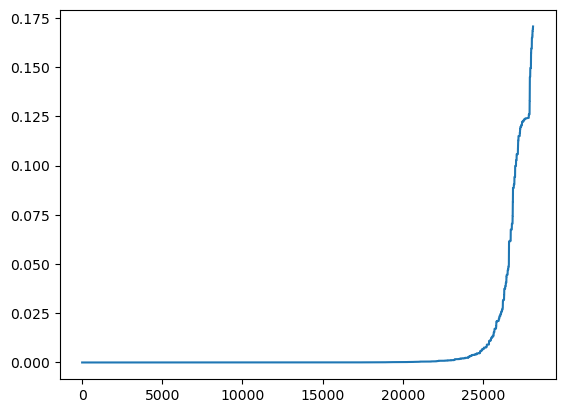

In [73]:
plt.plot(sorted_impact)

In [97]:
horizon_impact([500, 500, 0.1, 1, 1, 0.99, 0.5, 1, 0.1])

np.float64(0.011205997939287317)

In [98]:
np.array(sorted_impact)[(np.array(sorted_product)[:, [3, 4, 6]] == [1,1,0.5]).all(axis=1)][-1], np.array(sorted_product)[(np.array(sorted_product)[:, [3, 4, 6]] == [1,1,0.5]).all(axis=1)][-1]

(np.float64(0.011205997939287317),
 array([5.0e+02, 5.0e+02, 1.0e-01, 1.0e+00, 1.0e+00, 9.9e-01, 5.0e-01,
        1.0e+00, 1.0e-01]))

### Augment land size

In [13]:
conductivity = 0.1
params = {"land_size": (1000, 1000),
          "selling_price": 0.1,
          "max_yield": 1,
          "max_Kc": 1,
          "intermediate_yield": 0.95,
          "electricity_price": 0.5,
          "alpha_price": [1]}

shutil.copyfile(parameter_file, new_parameter_file)
with open(new_parameter_file, 'r+') as f:
    data = json.load(f)
    # modify field
    data['physical']['hk'] = conductivity
    # overwrite file
    f.seek(0)
    json.dump(data, f, indent=4)
    f.truncate()
model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)
# Initialize Controller
controller_1 = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs',
    overwrite_time_horizon=1
)
controller_10 = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs',
    overwrite_time_horizon=10
)
# Model useful variables
A = model.A
Id_minus_A_inv = np.linalg.inv(np.eye(A.shape[0]) - A)
B0, B1 = model.B_v
Cinvt = model.C.T @ Id_minus_A_inv.T


# Construct quadratic and linear cost matrices
Ri_v_quad, Li_v_quad = _compute_irrigation_cost_matrices(params)
# Scale pumping cost
ep = 10e-5 * params['electricity_price'] / quad_cost.extraction_cost[0]
Rp_v  = ep * np.array(quad_cost.Rp_v)
Rp_v_minus = ep * np.array(quad_cost.Rp_v_minus)
Mp_v  = ep * np.array(quad_cost.Mp_v)
Lp_v  = ep * np.array(quad_cost.Lp_v)
Rp_v_minus_1, Rp_v_minus_10 = repeat_matrix(Rp_v_minus)
Mp_v_1, Mp_v_10 = repeat_matrix(Mp_v)
# Iterate over varying quadratic reward importance
for i_alpha, alpha in enumerate(params["alpha_price"]):   # TODO: add linear cost if we want other alpha than 1.
    # Construct cost matrices
    R_v = alpha * np.array(Ri_v_quad) + Rp_v
    L_v = alpha * np.array(Li_v_quad) + Lp_v # + (1 - alpha) * np.array(Li_v_lin)
    R_v_1, R_v_10 = repeat_matrix(R_v)
    L_v_1, L_v_10 = repeat_matrix(L_v)
    controller_1.update_cost_matrices(None, R_v_1, Rp_v_minus_1, Mp_v_1, L_v_1)
    controller_10.update_cost_matrices(None, R_v_10, Rp_v_minus_10, Mp_v_10, L_v_10)
    # Solve optimization problem and reorganize inputs
    input_1, _ = controller_1._solve_problem(x_0)
    input_10, _ = controller_10._solve_problem(x_0)
    input_1 = controller_1._solution_to_command(input_1)
    input_10 = controller_10._solution_to_command(input_10)

In [14]:
input_1[0,0], input_1[0,4], input_10[0,0], input_10[0,4]

(np.float64(-4880.968719577525),
 np.float64(-4880.968719577516),
 np.float64(-4377.301053826693),
 np.float64(-4377.3010538266835))

In [15]:
abs(input_1[0,0] - input_10[0,0])/abs(input_10[0,0]), abs(input_10[0,4] - input_1[0,4])/abs(input_10[0,4])

(np.float64(0.11506351963398077), np.float64(0.11506351963398101))

Augmenting land size augment the divergence.

Remark: Augmenting land size is equivalent to reducing a without touching b => quadratic function gets closer to affine.

In [24]:
controller_10 = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A, model.B_v, model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs',
    overwrite_time_horizon=10
)

In [25]:
controller_10.update_cost_matrices(None, R_v_10, Rp_v_minus_10, Mp_v_10, L_v_10)